# Modelo de Precificação de Imóveis — Ilhéus e Itabuna/BA

Notebook didático (nível: iniciante em MBA de dados) que constrói, de ponta a ponta, um modelo simples para **prever o preço de imóveis** a partir da tabela `workspace.default.anuncios` (~846 anúncios).

**Roteiro:**
1. **Coleta** — leitura da tabela com Spark e conversão para pandas
2. **Análise (EDA)** — preço por portal, cidade e bairro, com gráficos interativos
3. **Tratamento** — features, OneHotEncoder, StandardScaler e split 80/20
4. **Modelagem** — primeiro a Regressão Linear (com a reta projetada real x previsto), depois separadamente a Árvore de Decisão
5. **Plot da árvore + SHAP** — regras de decisão e importância das features (impacto em R$)
6. **Comparação** — MAE, RMSE e R² (e escolha do melhor modelo)
7. **Previsão de imóvel novo** — função para informar metragem, bairro, etc. e receber o valor do aluguel previsto
8. **Projeção** — cenários do valor do aluguel em Ilhéus e Itabuna para os próximos 5 anos
9. **Exportação** — tabelas no Unity Catalog que alimentam o dashboard (site da locadora)
10. **Conclusão** — aprendizados, limitações e próximos passos

In [0]:
%pip install plotly shap --quiet

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# ============================================================
# ETAPA 1 — COLETA DE DADOS
# ============================================================
# A tabela 'workspace.default.anuncios' já existe no catálogo (criada previamente a partir do CSV).
# Lemos com Spark e convertemos para pandas, que é mais prático para a modelagem.
import pandas as pd

df = spark.table("workspace.default.anuncios").toPandas()

# Garantir tipos numéricos corretos (converte e marca como NaN o que não for número)
for coluna in ["preco", "area_m2", "quartos", "banheiros", "preco_m2"]:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

print("Linhas carregadas:", len(df))
print("Colunas:", list(df.columns))
display(df.head(5))

Linhas carregadas: 846
Colunas: ['portal', 'id_anuncio', 'cidade', 'bairro_texto', 'bairro_url', 'tipo', 'preco', 'area_m2', 'quartos', 'banheiros', 'pagina', 'url', 'coletado_em', 'bairro', 'residencial', 'preco_m2']


portal,id_anuncio,cidade,bairro_texto,bairro_url,tipo,preco,area_m2,quartos,banheiros,pagina,url,coletado_em,bairro,residencial,preco_m2
vivareal,2907867724,Ilhéus,Pontal,pontal,Apartment,4000.0,120.0,3.0,1.0,1,https://www.vivareal.com.br/imovel/apartamento-3-quartos-pontal-bairros-ilheus-com-garagem-120m2-aluguel-RS4000-id-2907867724/,2026-11-06 23:38,Pontal,true,33.3
vivareal,2902416120,Ilhéus,Nossa Senhora da Vitória,nossa senhora da vitoria,Apartment,4500.0,76.0,2.0,2.0,1,https://www.vivareal.com.br/imovel/apartamento-2-quartos-nossa-senhora-da-vitoria-bairros-ilheus-com-garagem-76m2-aluguel-RS4500-id-2902416120/,2026-11-06 23:38,Nossa Senhora Da Vitoria,true,59.2
vivareal,2919632298,Ilhéus,Teresópolis,teresopolis,Apartment,2200.0,72.0,2.0,2.0,1,https://www.vivareal.com.br/imovel/apartamento-2-quartos-teresopolis-bairros-ilheus-com-garagem-72m2-aluguel-RS2200-id-2919632298/,2026-11-06 23:38,Teresopolis,true,30.6
vivareal,2898618909,Ilhéus,Nossa Senhora da Vitória,nossa senhora da vitoria,Apartment,2700.0,70.0,2.0,2.0,1,https://www.vivareal.com.br/imovel/apartamento-2-quartos-nossa-senhora-da-vitoria-bairros-ilheus-com-garagem-70m2-aluguel-RS2700-id-2898618909/,2026-11-06 23:38,Nossa Senhora Da Vitoria,true,38.6
vivareal,2919960233,Ilhéus,Nossa Senhora da Vitória,nossa senhora da vitoria,Apartment,3850.0,76.0,2.0,2.0,1,https://www.vivareal.com.br/imovel/apartamento-2-quartos-nossa-senhora-da-vitoria-bairros-ilheus-com-garagem-76m2-aluguel-RS3850-id-2919960233/,2026-11-06 23:38,Nossa Senhora Da Vitoria,true,50.7


In [0]:
# ============================================================
# ETAPA 2 (preparação) — LIMPEZA / FILTROS DE QUALIDADE
# ============================================================
# Dados raspados de portais têm sujeira. Motivo de cada filtro:
# 1) preco não nulo e area_m2 > 0: sem preço/área não dá para modelar.
# 2) residencial = True: lojas e terrenos comerciais têm lógica de preço diferente de casas/apartamentos.
# 3) preco_m2 entre 5 e 200: a base é de ALUGUEL mensal (as URLs dos anúncios trazem
#    'aluguel-RS...'), e o aluguel por m² da região gira nessa faixa (mediana ~R$ 40/m²).
#    Fora dela há vendas de terrenos (R$ 400 em 500 m² = R$ 0,80/m²) e erros de coleta
#    (R$ 2.200 em 2 m² = R$ 1.100/m²).
# 4) area_m2 <= 1000: áreas gigantes são fazendas/terrenos especiais que distorcem o modelo.
# 5) DEDUPLICAÇÃO: o mesmo imóvel aparece em vários portais (ex.: vivareal e chavesnamao).
#    Mantemos a 1ª ocorrência de cada combinação cidade+bairro+tipo+quartos+banheiros+área+preço.
linhas_originais = len(df)

filtro = (
    df["preco"].notna()
    & (df["area_m2"] > 0)
    & (df["residencial"] == True)
    & df["preco_m2"].between(5, 200)
    & (df["area_m2"] <= 1000)
)
df_limpo = df[filtro].copy()
linhas_pos_filtro = len(df_limpo)

df_limpo = df_limpo.drop_duplicates(
    subset=["cidade", "bairro", "tipo", "quartos", "banheiros", "area_m2", "preco"]
)
print(f"Original: {linhas_originais} | após filtros de qualidade: {linhas_pos_filtro} | após deduplicação: {len(df_limpo)}")

# View temporária para usar SQL na EDA
spark.createDataFrame(df_limpo).createOrReplaceTempView("anuncios_limpos")

Original: 846 | após filtros de qualidade: 587 | após deduplicação: 554


In [0]:
# ============================================================
# ETAPA 2a — EDA: PREÇO POR PORTAL (FONTE DO ANÚNCIO)
# ============================================================
# Cada portal (vivareal, zap, chavesnamao) tem perfil de oferta diferente.
# MEDIAN é mais robusta que AVG quando há valores altos atípicos.
# Os gráficos ao lado da tabela são interativos: clique na legenda/eixo para filtrar.
display(spark.sql("""
    SELECT portal AS fonte,
           COUNT(*) AS anuncios,
           ROUND(MEDIAN(preco), 0) AS preco_mediano,
           ROUND(AVG(preco), 0) AS preco_medio,
           ROUND(MEDIAN(preco_m2), 1) AS preco_m2_mediano
    FROM anuncios_limpos
    GROUP BY portal
    ORDER BY anuncios DESC
"""))

# Gráficos interativos (plotly): passe o mouse sobre as barras para ver os valores;
# use a legenda e os botões do canto superior direito (zoom, seleção) para filtrar.
import plotly.express as px
eda_portal = spark.sql("""
    SELECT portal AS fonte, COUNT(*) AS anuncios,
           ROUND(MEDIAN(preco), 0) AS preco_mediano,
           ROUND(MEDIAN(preco_m2), 1) AS preco_m2_mediano
    FROM anuncios_limpos
    GROUP BY portal
""").toPandas()
px.bar(eda_portal, x="fonte", y="preco_mediano", color="fonte", hover_data=["anuncios"],
       title="ETAPA 2a — Preço mediano por portal (R$)").show()
px.bar(eda_portal, x="fonte", y="preco_m2_mediano", color="fonte", hover_data=["anuncios"],
       title="ETAPA 2a — Preço por m² mediano por portal (R$/m²)").show()

# Preço separado por FONTE e CIDADE: o mesmo portal pode ter perfis diferentes em cada cidade.
# Tabela com o cruzamento portal x cidade:
display(spark.sql("""
    SELECT portal AS fonte, cidade, COUNT(*) AS anuncios,
           ROUND(MEDIAN(preco), 0) AS preco_mediano,
           ROUND(MEDIAN(preco_m2), 1) AS preco_m2_mediano
    FROM anuncios_limpos
    GROUP BY portal, cidade
    ORDER BY fonte, cidade
"""))

# Gráficos interativos (plotly) do cruzamento fonte x cidade:
# barras lado a lado (barmode="group"), coloridas por cidade — clique na legenda para filtrar.
eda_portal_cidade = spark.sql("""
    SELECT portal AS fonte, cidade, COUNT(*) AS anuncios,
           ROUND(MEDIAN(preco), 0) AS preco_mediano,
           ROUND(MEDIAN(preco_m2), 1) AS preco_m2_mediano
    FROM anuncios_limpos
    GROUP BY portal, cidade
    ORDER BY fonte, cidade
""").toPandas()
px.bar(eda_portal_cidade, x="fonte", y="preco_mediano", color="cidade", barmode="group",
       hover_data=["anuncios"],
       title="ETAPA 2a — Preço mediano por portal e cidade (R$)").show()
px.bar(eda_portal_cidade, x="fonte", y="preco_m2_mediano", color="cidade", barmode="group",
       hover_data=["anuncios"],
       title="ETAPA 2a — Preço por m² mediano por portal e cidade (R$/m²)").show()

fonte,anuncios,preco_mediano,preco_medio,preco_m2_mediano
vivareal,495,3500.0,4373.0,39.2
zap,45,3000.0,3425.0,40.0
chavesnamao,14,2950.0,4889.0,32.3


<!doctype html>

<!doctype html>

fonte,cidade,anuncios,preco_mediano,preco_m2_mediano
chavesnamao,Ilhéus,13,3000.0,28.8
chavesnamao,Itabuna,1,1950.0,55.7
vivareal,Ilhéus,445,3599.0,40.0
vivareal,Itabuna,50,2850.0,18.7
zap,Ilhéus,45,3000.0,40.0


<!doctype html>

<!doctype html>

In [0]:
# ============================================================
# ETAPA 2b — EDA: PREÇO POR CIDADE (Ilhéus x Itabuna)
# ============================================================
display(spark.sql("""
    SELECT cidade,
           COUNT(*) AS anuncios,
           ROUND(MEDIAN(preco), 0) AS preco_mediano,
           ROUND(AVG(preco), 0) AS preco_medio,
           ROUND(MEDIAN(preco_m2), 1) AS preco_m2_mediano
    FROM anuncios_limpos
    GROUP BY cidade
    ORDER BY anuncios DESC
"""))

# Gráfico interativo (plotly): passe o mouse sobre as barras para ver os valores.
import plotly.express as px
eda_cidade = spark.sql("""
    SELECT cidade, COUNT(*) AS anuncios,
           ROUND(MEDIAN(preco), 0) AS preco_mediano
    FROM anuncios_limpos
    GROUP BY cidade
""").toPandas()
px.bar(eda_cidade, x="cidade", y="preco_mediano", color="cidade", hover_data=["anuncios"],
       title="ETAPA 2b — Preço mediano por cidade (R$)").show()

cidade,anuncios,preco_mediano,preco_medio,preco_m2_mediano
Ilhéus,503,3500.0,4315.0,40.0
Itabuna,51,2800.0,4251.0,19.0


<!doctype html>

In [0]:
# ============================================================
# ETAPA 2c — EDA: PREÇO POR CIDADE E BAIRRO (top 10 por volume)
# ============================================================
# Bairros com mais anúncios dão amostra mais confiável de preço.
display(spark.sql("""
    SELECT cidade, bairro, COUNT(*) AS anuncios,
           ROUND(MEDIAN(preco), 0) AS preco_mediano,
           ROUND(MEDIAN(preco_m2), 1) AS preco_m2_mediano
    FROM anuncios_limpos
    GROUP BY cidade, bairro
    ORDER BY anuncios DESC
    LIMIT 10
"""))

# Gráfico interativo (plotly): barras por bairro coloridas por cidade;
# clique na legenda para filtrar uma cidade e passe o mouse para ver os valores.
import plotly.express as px
eda_bairro = spark.sql("""
    SELECT cidade, bairro, COUNT(*) AS anuncios,
           ROUND(MEDIAN(preco), 0) AS preco_mediano
    FROM anuncios_limpos
    GROUP BY cidade, bairro
    ORDER BY anuncios DESC
    LIMIT 10
""").toPandas()
eda_bairro["bairro"] = eda_bairro["bairro"].fillna("(sem bairro)")
eda_bairro["bairro (cidade)"] = eda_bairro["bairro"] + " — " + eda_bairro["cidade"]
px.bar(eda_bairro, x="bairro (cidade)", y="preco_mediano", color="cidade", hover_data=["anuncios"],
       title="ETAPA 2c — Preço mediano por bairro, top 10 por volume (R$)"
      ).update_layout(xaxis_tickangle=-30).show()

cidade,bairro,anuncios,preco_mediano,preco_m2_mediano
Ilhéus,Nossa Senhora Da Vitoria,174,3450.0,43.1
Ilhéus,Sao Francisco,87,3500.0,41.7
Ilhéus,Pontal,48,3530.0,43.0
Ilhéus,Jardim Atlantico,30,5500.0,56.3
Ilhéus,Centro,22,4575.0,24.7
Ilhéus,Cidade Nova,20,4055.0,43.6
Ilhéus,Olivenca,16,3600.0,36.8
Ilhéus,Jardim Savoia,14,3000.0,26.7
Ilhéus,null,13,3000.0,40.7
Ilhéus,Conquista,10,2250.0,32.2


<!doctype html>

In [0]:
# ============================================================
# ETAPA 3 — TRATAMENTO DOS DADOS (features e target)
# ============================================================
# TARGET (o que queremos prever): preco (R$)
# FEATURES (informações que o modelo usa para prever):
#   numéricas  -> area_m2, quartos, banheiros
#   categóricas -> tipo (casa/apartamento), cidade, bairro, portal
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Bairros com poucos anúncios viram 'outros': evita dezenas de colunas quase vazias no OneHotEncoder
contagem_bairros = df_limpo["bairro"].value_counts()
bairros_comuns = contagem_bairros[contagem_bairros >= 15].index
df_modelo = df_limpo.copy()
df_modelo["bairro"] = df_modelo["bairro"].where(df_modelo["bairro"].isin(bairros_comuns), "outros")
print("Bairros mantidos (>= 15 anúncios):", sorted(set(bairros_comuns)))

features_num = ["area_m2", "quartos", "banheiros"]
features_cat = ["tipo", "cidade", "bairro", "portal"]
X = df_modelo[features_num + features_cat]  # entrada
y = df_modelo["preco"]                        # alvo


Bairros mantidos (>= 15 anúncios): ['Centro', 'Cidade Nova', 'Jardim Atlantico', 'Nossa Senhora Da Vitoria', 'Olivenca', 'Pontal', 'Sao Francisco']


In [0]:

# Split 80/20 com semente fixa (random_state=42) => reprodutível
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Treino: {len(X_treino)} imóveis | Teste: {len(X_teste)} imóveis")

# PRÉ-PROCESSAMENTO em um único ColumnTransformer:
#   StandardScaler (numéricas)  -> média 0 e desvio 1; coloca área e quartos na mesma escala.
#   OneHotEncoder (categóricas) -> 'cidade=Ilhéus' vira colunas de 0/1, pois modelos não leem texto.
def montar_preprocessador():
    return ColumnTransformer([
        ("num", StandardScaler(), features_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), features_cat),
    ])

Treino: 443 imóveis | Teste: 111 imóveis


In [0]:
# ============================================================
# ETAPA 4a — MODELO 1/2: REGRESSÃO LINEAR
# ============================================================
# A Regressão Linear estima o preço como uma soma ponderada das features:
#   preco ≈ w1×área + w2×quartos + w3×banheiros + pesos das categorias (one-hot)
# Pipeline = pré-processamento + modelo num único objeto (o pré-processador
# 'aprende' só com o TREINO, evitando vazamento de dados do teste).
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

modelo_lr = Pipeline([
    ("pre", montar_preprocessador()),
    ("reg", LinearRegression()),
])
modelo_lr.fit(X_treino, y_treino)
print("Regressão Linear treinada!")

# Tradução do modelo: cada peso (coeficiente) diz o efeito da feature no preço (após padronização)
import pandas as pd
nomes_lr = [n.split("__")[-1] for n in modelo_lr.named_steps["pre"].get_feature_names_out()]
coeficientes = (
    pd.Series(modelo_lr.named_steps["reg"].coef_, index=nomes_lr)
    .sort_values(key=abs, ascending=False)
    .head(10)
)
display(coeficientes.to_frame("peso_no_preco"))

# A RETA PROJETADA: preço real (eixo x) x preço previsto (eixo y) no conjunto de TESTE.
# A reta tracejada vermelha é a reta y = x — onde as previsões PERFEITAS cairiam.
# Quanto mais perto os pontos estiverem da reta, melhor o modelo prevê.
pred_lr = modelo_lr.predict(X_teste)
df_reta = pd.DataFrame({"preco_real": y_teste.values, "preco_previsto": pred_lr})
import plotly.express as px
fig = px.scatter(df_reta, x="preco_real", y="preco_previsto",
                 title="ETAPA 4a — Regressão Linear: preço real x previsto (teste)",
                 labels={"preco_real": "Preço real (R$)", "preco_previsto": "Preço previsto (R$)"})
limite = df_reta["preco_real"].max()
fig.add_shape(type="line", x0=0, y0=0, x1=limite, y1=limite,
              line=dict(color="red", dash="dash"), name="reta y = x (previsão perfeita)")
fig.show()

Regressão Linear treinada!


peso_no_preco
1712.4977573533004
-1252.0681115972875
1074.5119415552897
902.7782453813915
874.7320083037569
524.7711649076698
-524.7711649076673
-517.6281003325524
483.3291704350204
-460.4296457560071


<!doctype html>

In [0]:
# ============================================================
# ETAPA 4b — MODELO 2/2: ÁRVORE DE DECISÃO
# ============================================================
# A árvore aprende REGRAS do tipo "SE área <= X E bairro = Y ENTÃO preço = Z",
# capturando relações que não são uma reta (ex.: preço/m² cai em imóveis grandes).
# max_depth=5 mantém a árvore rasa: legível e com menos overfitting.
from sklearn.tree import DecisionTreeRegressor

modelo_arv = Pipeline([
    ("pre", montar_preprocessador()),
    ("arv", DecisionTreeRegressor(max_depth=5, random_state=42)),
])
modelo_arv.fit(X_treino, y_treino)
print("Árvore de Decisão treinada! (as regras são plotadas na ETAPA 5)")

# Preço REAL x PREVISTO também na árvore (igual ao gráfico da Regressão Linear na ETAPA 4a):
# cada ponto é um imóvel do conjunto de teste; a reta tracejada vermelha (y = x) é onde as
# previsões PERFEITAS cairiam. Repare nos 'degraus' horizontais: a árvore só devolve
# um valor fixo por folha (por isso são poucos valores distintos de previsão).
pred_arv = modelo_arv.predict(X_teste)
df_reta_arv = pd.DataFrame({"preco_real": y_teste.values, "preco_previsto": pred_arv})
import plotly.express as px
fig = px.scatter(df_reta_arv, x="preco_real", y="preco_previsto",
                 title="ETAPA 4b — Árvore de Decisão: preço real x previsto (teste)",
                 labels={"preco_real": "Preço real (R$)", "preco_previsto": "Preço previsto (R$)"})
limite = max(df_reta_arv["preco_real"].max(), df_reta_arv["preco_previsto"].max())
fig.add_shape(type="line", x0=0, y0=0, x1=limite, y1=limite,
              line=dict(color="red", dash="dash"), name="reta y = x (previsão perfeita)")
fig.show()

Árvore de Decisão treinada! (as regras são plotadas na ETAPA 5)


<!doctype html>

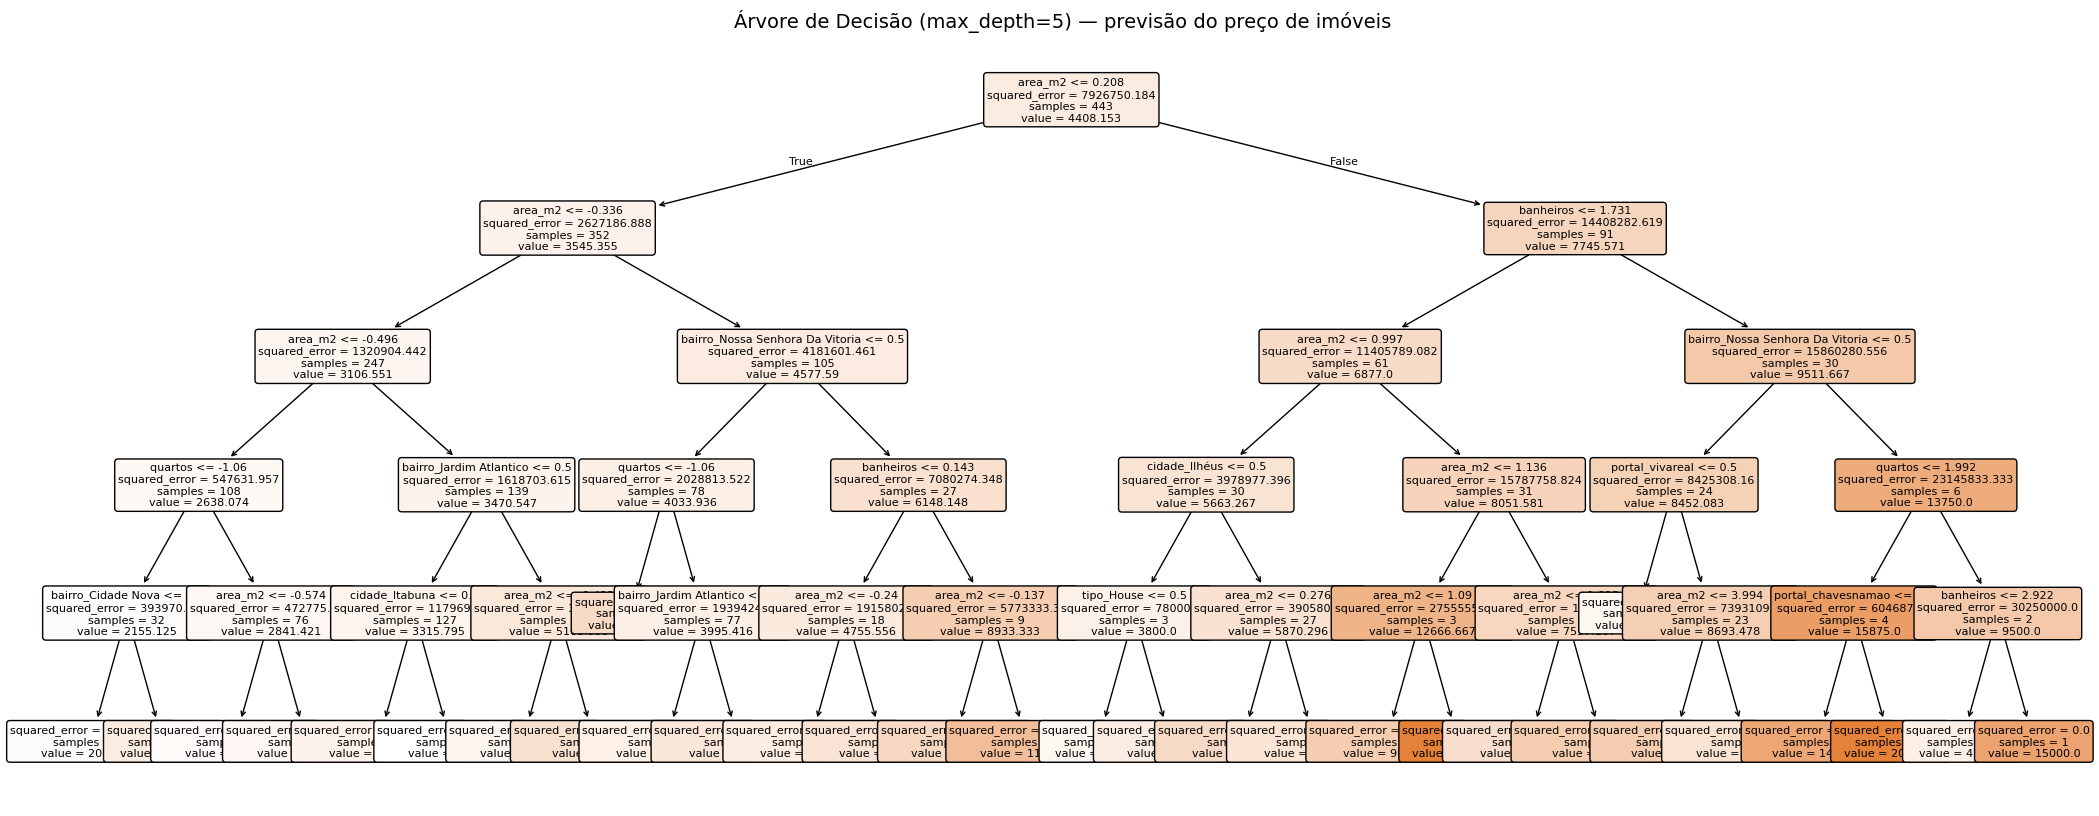

|--- area_m2 <= 0.21
|   |--- area_m2 <= -0.34
|   |   |--- area_m2 <= -0.50
|   |   |   |--- quartos <= -1.06
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- quartos >  -1.06
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- area_m2 >  -0.50
|   |   |   |--- bairro_Jardim Atlantico <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- bairro_Jardim Atlantico >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- area_m2 >  -0.34
|   |   |--- bairro_Nossa Senhora Da Vitoria <= 0.50
|   |   |   |--- quartos <= -1.06
|   |   |   |   |--- value: [7000.00]
|   |   |   |--- quartos >  -1.06
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- bairro_Nossa Senhora Da Vitoria >  0.50
|   |   |   |--- banheiros <= 0.14
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- banheiros >  0.14
|   |   |   |   |--- truncated branch of depth 2
|--- area_m2 >  0.21
|   |--- banheiros <= 1.73
|   |   |--- area_m2 <= 1.00

In [0]:
# ============================================================
# ETAPA 5 — PLOT DA ÁRVORE DE DECISÃO (regras de decisão)
# ============================================================
# Como ler a árvore:
#   - Cada pergunta é do tipo "feature <= valor?" (sim vai à esquerda, não à direita).
#   - Em cinza-azulado: área_m2 e quartos numéricos já PADRONIZADOS pelo StandardScaler
#     (valor 0 = média do treino; negativo = abaixo da média).
#   - "value" = preço médio dos imóveis naquele nó; "samples" = quantos imóveis caem ali.
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, export_text

arv = modelo_arv.named_steps["arv"]
nomes = [n.split("__")[-1] for n in modelo_arv.named_steps["pre"].get_feature_names_out()]

plt.figure(figsize=(26, 10))
plot_tree(arv, feature_names=nomes, filled=True, rounded=True, fontsize=8)
plt.title("Árvore de Decisão (max_depth=5) — previsão do preço de imóveis", fontsize=14)
plt.show()

# Versão em TEXTO (mais fácil de ler) — primeiros 3 níveis
print(export_text(arv, feature_names=nomes, max_depth=3))

In [0]:
# ============================================================
# ETAPA 5b — IMPORTÂNCIA DAS FEATURES DA ÁRVORE (com SHAP)
# ============================================================
# Duas formas de medir o que a árvore usa para decidir:
# 1) feature_importances_ (embutida no sklearn): quanto cada coluna ajudou a
#    reduzir o erro ao dividir os nós. Fica entre 0 e 1 e soma 1.0.
# 2) SHAP (TreeExplainer): para CADA imóvel, quanto cada feature empurrou a
#    previsão para cima/baixo em relação ao aluguel médio (base value).
#    O resultado sai em R$ — muito mais intuitivo: 'a área mexe R$ X na previsão'.
import shap
import numpy as np
import plotly.express as px

arv = modelo_arv.named_steps["arv"]
nomes = [n.split("__")[-1] for n in modelo_arv.named_steps["pre"].get_feature_names_out()]

# 1) Importância embutida da árvore (por coluna transformada; soma 1.0)
importancia = (pd.DataFrame({"feature": nomes, "importancia": arv.feature_importances_})
               .sort_values("importancia", ascending=False))
px.bar(importancia, x="feature", y="importancia", color="feature",
       title="ETAPA 5b — Importância embutida da árvore por coluna (soma 1.0)").show()

# 2) SHAP na árvore: explicamos as previsões do conjunto de TESTE.
#    Detalhe técnico: a árvore consome as features JÁ TRANSFORMADAS (padronizadas
#    e one-hot), então calculamos o SHAP nessa matriz e depois SOMAMOS as colunas
#    one-hot de cada feature original (bairro = soma das colunas dos bairros, etc.).
X_teste_transf = modelo_arv.named_steps["pre"].transform(X_teste)
if hasattr(X_teste_transf, "toarray"):   # OneHotEncoder pode devolver matriz esparsa
    X_teste_transf = X_teste_transf.toarray()

explainer = shap.TreeExplainer(arv)
shap_valores = explainer.shap_values(X_teste_transf)
base_value = float(np.ravel(explainer.expected_value)[0])
print(f"Base value (aluguel de partida, sem nenhuma informação): R$ {base_value:,.0f}".replace(",", "."))

def feature_origem(nome_transf):
    """Devolve a feature original de uma coluna transformada (bairro_X -> bairro)."""
    for f in features_cat:
        if nome_transf.startswith(f + "_"):
            return f
    return nome_transf  # coluna numérica (nome igual)

shap_df = pd.DataFrame(shap_valores, columns=nomes)
impacto = (pd.DataFrame({"feature": [feature_origem(c) for c in nomes],
                         "impacto": np.abs(shap_df).mean().values})
           .groupby("feature", as_index=False)["impacto"].sum()
           .sort_values("impacto", ascending=False))
impacto["impacto_medio_abs_R$"] = impacto["impacto"].round(1)
display(impacto[["feature", "impacto_medio_abs_R$"]])
px.bar(impacto, x="feature", y="impacto_medio_abs_R$", color="feature",
       title="ETAPA 5b — SHAP: impacto médio absoluto por feature (R$/mês)").show()

<!doctype html>

Base value (aluguel de partida. sem nenhuma informação): R$ 4.408


feature,impacto_medio_abs_R$
area_m2,1346.2
bairro,460.3
banheiros,334.0
cidade,90.3
quartos,88.8
portal,63.9
tipo,6.4


<!doctype html>

In [0]:
# ============================================================
# ETAPA 6 — COMPARAÇÃO DOS MODELOS (MAE, RMSE e R²)
# ============================================================
# Métricas no conjunto de TESTE (dados que o modelo nunca viu):
#   MAE  -> erro médio absoluto em R$ ("na média, erra R$ X")
#   RMSE -> raiz do erro quadrático médio, penaliza erros grandes
#   R²   -> proporção da variação do preço explicada pelo modelo (1 = perfeito)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def avaliar(modelo, nome):
    pred = modelo.predict(X_teste)
    return {
        "modelo": nome,
        "MAE": round(mean_absolute_error(y_teste, pred), 1),
        "RMSE": round(np.sqrt(mean_squared_error(y_teste, pred)), 1),
        "R2": round(r2_score(y_teste, pred), 3),
    }

resultados = pd.DataFrame([
    avaliar(modelo_lr, "Regressão Linear"),
    avaliar(modelo_arv, "Árvore de Decisão"),
])
display(resultados)  # use as abas de gráfico ao lado para ver barras comparando os modelos

# Importância de cada feature segundo a árvore (soma 1.0)
importancias = (
    pd.DataFrame({"feature": nomes, "importancia": arv.feature_importances_})
    .sort_values("importancia", ascending=False)
    .head(10)
)
display(importancias)

# Gráficos interativos (plotly): passe o mouse sobre as barras para ver os valores.
# MAE e RMSE estão em R$ (menor = melhor); R² é adimensional (mais perto de 1 = melhor).
import plotly.express as px
comparacao_erros = resultados.melt(id_vars="modelo", value_vars=["MAE", "RMSE"],
                                   var_name="métrica", value_name="erro (R$)")
px.bar(comparacao_erros, x="modelo", y="erro (R$)", color="métrica", barmode="group",
       title="ETAPA 6 — MAE e RMSE por modelo (R$) — menor é melhor").show()
px.bar(resultados, x="modelo", y="R2", color="modelo",
       title="ETAPA 6 — R² por modelo — mais perto de 1 é melhor").show()

modelo,MAE,RMSE,R2
Regressão Linear,1483.1,2098.0,0.179
Árvore de Decisão,1279.7,1816.3,0.384


feature,importancia
area_m2,0.7141958228072303
banheiros,0.1168561082570264
bairro_Nossa Senhora Da Vitoria,0.08601965768446014
quartos,0.028256291853398903
bairro_Jardim Atlantico,0.01686980700553794
portal_vivareal,0.01233133951768427
cidade_Itabuna,0.009695088742156582
portal_chavesnamao,0.008697642243084103
cidade_Ilhéus,0.004436532549674043
bairro_Cidade Nova,0.002175918251026625


<!doctype html>

<!doctype html>

In [0]:
# ============================================================
# ETAPA 6b — USANDO O MELHOR MODELO: PREVER UM IMÓVEL NOVO
# ============================================================
# Primeiro, escolhemos automaticamente o melhor modelo pela comparação da ETAPA 6 (maior R²):
melhor = resultados.loc[resultados["R2"].idxmax()]
melhor_modelo = modelo_arv if melhor["modelo"] == "Árvore de Decisão" else modelo_lr
print("Melhor modelo:", melhor["modelo"], "— R² =", melhor["R2"])

# Função para o ALUNO inserir os dados de um imóvel novo e receber o preço previsto.
# Como usar: chame prever_preco(...) trocando os valores abaixo e rode a célula de novo.
#   - area_m2, quartos, banheiros -> números
#   - bairro  -> se NÃO estiver na lista de bairros conhecidos, entra como 'outros'
#   - cidade  -> 'Ilhéus' ou 'Itabuna' | tipo -> 'Apartment', 'House', ...
#   - portal  -> 'vivareal', 'zap' ou 'chavesnamao'
# Obs.: as URLs dos anúncios confirmam que a base é de ALUGUEL mensal (540 de 554
# anúncios têm 'aluguel' na URL, nenhum tem 'venda'), então a função devolve o
# VALOR DO ALUGUEL MENSAL previsto (R$/mês), não o preço de venda.
def prever_preco(area_m2, bairro, cidade="Ilhéus", tipo="Apartment",
                 quartos=2, banheiros=1, portal="vivareal"):
    """Prevê o valor do aluguel mensal (R$) de um imóvel novo com o melhor modelo treinado."""
    # 1) Bairro desconhecido vira 'outros' (mesma regra aplicada no treinamento)
    bairros_conhecidos = set(bairros_comuns) | {"outros"}
    bairro_final = bairro if bairro in bairros_conhecidos else "outros"
    if bairro_final != bairro:
        print(f"  Aviso: bairro '{bairro}' não está na base → usando 'outros'")

    # 2) Monta o imóvel novo no MESMO formato das features de treinamento
    imovel_novo = pd.DataFrame([{
        "area_m2": area_m2,
        "quartos": quartos,
        "banheiros": banheiros,
        "tipo": tipo,
        "cidade": cidade,
        "bairro": bairro_final,
        "portal": portal,
    }])[features_num + features_cat]

    # 3) Aplica o melhor modelo e devolve o preço previsto arredondado
    preco_previsto = melhor_modelo.predict(imovel_novo)[0]
    return round(preco_previsto)

# ===== EXEMPLOS DE USO (troque os valores e rode novamente!) =====
print("1) Apartamento 80 m², 2 quartos, 1 banheiro, Sao Francisco (Ilhéus):")
print("   Aluguel previsto: R$", prever_preco(80, "Sao Francisco", "Ilhéus", "Apartment", 2, 1))

print("2) Casa 150 m², 3 quartos, 2 banheiros, bairro que NÃO existe na base:")
print("   Aluguel previsto: R$", prever_preco(150, "Bairro Novo Qualquer", "Ilhéus", "House", 3, 2))

print("3) Apartamento 60 m², 2 quartos, 1 banheiro, Centro (Itabuna):")
print("   Aluguel previsto: R$", prever_preco(60, "Centro", "Itabuna", "Apartment", 2, 1))

Melhor modelo: Árvore de Decisão — R² = 0.384
1) Apartamento 80 m², 2 quartos, 1 banheiro, Sao Francisco (Ilhéus):
   Aluguel previsto: R$ 3439
2) Casa 150 m², 3 quartos, 2 banheiros, bairro que NÃO existe na base:
  Aviso: bairro 'Bairro Novo Qualquer' não está na base → usando 'outros'
   Aluguel previsto: R$ 3897
3) Apartamento 60 m², 2 quartos, 1 banheiro, Centro (Itabuna):
   Aluguel previsto: R$ 2946


In [0]:
# ============================================================
# ETAPA 6c — PROJEÇÃO DO VALOR DO ALUGUEL (próximos anos)
# ============================================================
# ATENÇÃO — o que os dados permitem e o que NÃO permitem:
# a base é um RETRATO de um único dia (todos os anúncios foram coletados em
# 2026-11-06 entre 23:38 e 23:42), então NÃO existe histórico (série temporal)
# para estimar tendência. Sem histórico, não há previsão estatística de futuro.
# O que dá para fazer de forma honesta: CENÁRIOS — aplicamos taxas de crescimento
# anual HIPOTÉTICAS sobre o aluguel mediano de hoje e vemos para onde cada
# cenário leva. Para uma projeção real, colete a base todo mês e use
# Prophet/ARIMA sobre a série histórica (ver 'Próximos passos' na Conclusão).

# Ponto de partida: aluguel mediano ATUAL por cidade (base de 2026)
atual = df_limpo.groupby("cidade")["preco"].median()

anos = list(range(2026, 2032))  # hoje + 5 anos

# Cenários de crescimento anual do aluguel (hipóteses didáticas):
#   Conservador 3%/ano | Base 6%/ano (próximo da inflação de serviços) | Aquecido 10%/ano
cenarios = {"Conservador (3%/ano)": 0.03, "Base (6%/ano)": 0.06, "Aquecido (10%/ano)": 0.10}

linhas = []
for cidade, preco_atual in atual.items():
    for rotulo, taxa in cenarios.items():
        for i, ano in enumerate(anos):
            linhas.append({"cidade": cidade, "cenário": rotulo, "ano": ano,
                           "aluguel_mediano": round(preco_atual * (1 + taxa) ** i)})
projecao = pd.DataFrame(linhas)
display(projecao)

# Gráfico interativo: um painel por cenário, uma linha por cidade.
# Clique na legenda para ligar/desligar uma cidade; passe o mouse para ver os valores.
import plotly.express as px
px.line(projecao, x="ano", y="aluguel_mediano", color="cidade", facet_col="cenário",
        markers=True,
        title="ETAPA 6c — Projeção do aluguel mediano de Ilhéus e Itabuna por cenário (R$/mês)",
        labels={"aluguel_mediano": "Aluguel mediano (R$/mês)"}).show()

cidade,cenário,ano,aluguel_mediano
Ilhéus,Conservador (3%/ano),2026,3500
Ilhéus,Conservador (3%/ano),2027,3605
Ilhéus,Conservador (3%/ano),2028,3713
Ilhéus,Conservador (3%/ano),2029,3825
Ilhéus,Conservador (3%/ano),2030,3939
Ilhéus,Conservador (3%/ano),2031,4057
Ilhéus,Base (6%/ano),2026,3500
Ilhéus,Base (6%/ano),2027,3710
Ilhéus,Base (6%/ano),2028,3933
Ilhéus,Base (6%/ano),2029,4169


<!doctype html>

In [0]:
# ============================================================
# ETAPA 8 — EXPORTAR DADOS PARA O DASHBOARD ("site da locadora")
# ============================================================
# O dashboard (AI/BI) não roda modelos Python: ele consulta TABELAS.
# Então exportamos duas tabelas para o Unity Catalog:
#   1) workspace.default.anuncios_limpos    -> base limpa (gráficos de EDA do dashboard)
#   2) workspace.default.previsoes_aluguel  -> "menu" do site: para cada combinação de
#      cidade x bairro x tipo x quartos x banheiros x área (de 10 em 10 m², de 20 a 300),
#      o aluguel previsto pelo melhor modelo. No dashboard, a pessoa escolhe as
#      características (filtros) e vê o valor previsto — como num site de locadora.
import numpy as np

# 1) Base limpa para os gráficos
colunas = ["portal", "cidade", "bairro", "tipo", "quartos", "banheiros", "area_m2", "preco", "preco_m2"]
spark.createDataFrame(df_limpo[colunas]).write.mode("overwrite").saveAsTable("workspace.default.anuncios_limpos")

# 2) Grade de previsões do melhor modelo (portal fixado em 'vivareal': impacto pequeno)
combos_cidade_bairro = df_modelo[["cidade", "bairro"]].drop_duplicates()
tipos = sorted(df_limpo["tipo"].unique())
areas = list(range(20, 301, 10))       # de 20 a 300 m², de 10 em 10
grade = []
for _, cb in combos_cidade_bairro.iterrows():
    for tipo in tipos:
        for q in [1, 2, 3, 4]:
            for b in [1, 2, 3]:
                for a in areas:
                    grade.append({"cidade": cb["cidade"], "bairro": cb["bairro"], "tipo": tipo,
                                  "quartos": q, "banheiros": b, "area_m2": a})
grade = pd.DataFrame(grade)
grade["portal"] = "vivareal"
grade["aluguel_previsto"] = melhor_modelo.predict(grade[features_num + features_cat]).round(0).astype(int)
grade["preco_m2_previsto"] = (grade["aluguel_previsto"] / grade["area_m2"]).round(1)
grade = grade[["cidade", "bairro", "tipo", "quartos", "banheiros", "area_m2",
               "aluguel_previsto", "preco_m2_previsto"]]
spark.createDataFrame(grade).write.mode("overwrite").saveAsTable("workspace.default.previsoes_aluguel")

print(f"Tabela anuncios_limpos criada: {len(df_limpo)} imóveis")
print(f"Tabela previsoes_aluguel criada: {len(grade)} combinações prontas para o dashboard")
display(grade.head(10))

# ETAPA 7 — CONCLUSÃO

## Qual modelo foi melhor?
A **Árvore de Decisão** venceu em todas as métricas no conjunto de teste (111 imóveis, aluguéis mensais de R$ 1.000 a R$ 15.000, mediana R$ 3.300):

| Modelo | MAE | RMSE | R² |
| --- | --- | --- | --- |
| Regressão Linear | R$ 1.483 | R$ 2.098 | 0,18 |
| **Árvore de Decisão** | **R$ 1.280** | **R$ 1.816** | **0,38** |

**Por quê?** A relação entre área e preço não é uma reta: o preço/m² cai em imóveis grandes e o efeito do bairro só aparece acima de certos limites. A árvore captura essas "dobras" nos dados (soma de degraus), enquanto a regressão linear força uma reta.

## O que o modelo aprendeu
* **Área (m²) é de longe o fator mais importante**: ~71% da importância da árvore; na regressão linear, cada desvio-padrão de área acima da média soma ~R$ 1.075 ao preço previsto.
* **Banheiros (~12%) e o bairro pesam no preço**: o bairro *Nossa Senhora da Vitória* (~9%) e *Jardim Atlântico* elevam o valor previsto.
* **Tipo do imóvel**: apartamentos tendem a preços menores (coeficiente negativo) que casas e acomodações.
* **Portal e cidade têm pouca influência** depois de descontar área e bairro — ou seja, o preço depende mais do imóvel do que de onde ele foi anunciado.

## Limitações
* Base pequena: **554 imóveis** após limpeza e deduplicação (de 846 anúncios) — pouco para um modelo robusto.
* Apenas **2 cidades** (Ilhéus e Itabuna) — não generaliza para outras regiões.
* O target é o **valor do aluguel mensal** — as URLs confirmam (540 de 554 anúncios são de aluguel). O modelo **não prevê preço de venda**.
* R² de 0,38 significa que o modelo explica só **~38% da variação do preço** — o resto (acabamento, posição na rua, idade do imóvel) não está nos dados.

## Próximos passos
1. Coletar mais dados (mais cidades, mais bairros, mais atributos: condomínio, vaga, idade do imóvel).
2. Experimentar modelos mais fortes (Random Forest, Gradient Boosting) com validação cruzada.
3. Se o objetivo for prever preço de VENDA, coletar anúncios de venda em separado (a base atual é toda de aluguel).
4. Para a **projeção de aluguel virar previsão real**: coletar a base TODO MÊS (série histórica) e aplicar modelos de série temporal (Prophet, ARIMA) — hoje a base é um retrato de um único dia.